In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# B15 – Phát Hiện Mã Độc Không Cần Nhãn Mã Độc
## Isolation Forest, One-Class SVM & Local Outlier Factor – Dataset Malware-Benign

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
ROOT_DIR = Path.cwd()
_name = "Malware-Benign.csv"
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR.parent / "Dataset" / "malware-benignpe-files" / _name,
    ROOT_DIR / "Dataset" / "malware-benignpe-files" / _name,
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

LABEL_COL = "Malware"               # 0 = file lành tính, 1 = mã độc
TARGET_NAMES = ["Benign", "Malware"]
ID_COL = "Hash_md5_Name"
META_COLS = []

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 30% mẫu lành tính được giữ lại cho tập test

# ==========================
# SIÊU THAM SỐ BA PHƯƠNG PHÁP
# ==========================
N_TREES = 200                            # số cây của Isolation Forest
CONTAM_GRID = [0.01, 0.05, 0.1, 0.2]     # tỷ lệ bất thường giả định
PCTL_GRID = [90.0, 95.0, 97.5, 99.0, 99.5]   # phân vị dùng làm ngưỡng
NU_GRID = [0.01, 0.05, 0.1, 0.2]         # nu của One-Class SVM
OCSVM_GAMMA = ["scale", 0.01, 0.1]       # gamma của One-Class SVM
K_GRID = [5, 10, 20, 35, 50]             # n_neighbors của LOF
CURVE_GRID = [250, 500, 1000, 2000]      # cỡ tập train cho learning curve

# One-Class SVM và LOF đều đắt theo bình phương số mẫu nên huấn luyện trên
# tập con; Isolation Forest thì dùng toàn bộ tập train vì chi phí thấp.
OCSVM_MAX = 10000

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
CONTAM_COMMENT = (
    "\nNhận xét: F1 tăng từ 0,044 lên 0,703 khi contamination tăng từ 0,01 lên 0,2,\n"
    "nhưng AUC đứng yên quanh 0,834. Lý do giống bài của CV4.1: tập test có 89% mã\n"
    "độc nên gắn cờ càng nhiều thì F1 càng cao, mà điều đó không phản ánh năng lực\n"
    "phân biệt.\n"
    "Đáng lo hơn: AUC 0,834 là mức khá thấp — thấp hơn hẳn 0,970 của bộ dữ liệu lưu\n"
    "lượng mạng. Dấu hiệu sớm cho thấy phát hiện bất thường trên PE header khó hơn\n"
    "nhiều.")
PCTL_COMMENT = (
    "\nNhận xét: Recall cực thấp ở mọi phân vị — chỉ 0,221 ngay cả ở phân vị 90.\n"
    "Nghĩa là Isolation Forest bỏ sót gần 80% mã độc. Precision tuy cao (0,95)\n"
    "nhưng với mức Recall đó thì mô hình gần như vô dụng.\n"
    "Biểu đồ phân bố bên phải cho thấy nguyên nhân: điểm bất thường của mã độc\n"
    "CHỒNG LẤN gần như hoàn toàn với file lành tính. Giải thích hợp lý: mã độc được\n"
    "biên dịch bằng cùng những trình biên dịch, đóng gói bằng cùng những packer\n"
    "thương mại như phần mềm hợp pháp — nên PE header của chúng trông \"bình\n"
    "thường\". Chúng không phải ngoại lai về mặt thống kê.")
OCSVM_COMMENT = (
    "\nNhận xét: One-Class SVM với nu=0,2 và gamma=0,1 đạt F1 0,9141 — cao hơn hẳn\n"
    "Isolation Forest. Đáng chú ý là gamma=0,1 thắng ở mọi giá trị nu, tức biên bao\n"
    "cần khá cục bộ. Nhưng hãy giữ sự thận trọng: phần A6 sẽ cho thấy con số 0,91\n"
    "này vẫn chưa vượt được mốc so sánh tầm thường.")
LOF_COMMENT = (
    "\nNhận xét: LOF tốt nhất ở k=5 (0,7998) và GIẢM đơn điệu khi k tăng — ngược\n"
    "hẳn với bộ dữ liệu của CV4.1 (nơi k lớn thắng). Điều này nói rằng mã độc PE\n"
    "tạo thành rất nhiều cụm NHỎ: xét mật độ trong phạm vi 5 láng giềng thì thấy\n"
    "khác biệt, mở rộng ra 50 láng giềng thì khác biệt bị hòa tan.\n"
    "Phù hợp với hiểu biết miền: mỗi họ mã độc hoặc mỗi packer tạo một cụm riêng.")
COMPARE_COMMENT = (
    "\nNhận xét: KHÔNG phương pháp nào vượt được mốc tầm thường về F1 (0,94). Nếu\n"
    "chỉ nhìn F1, kết luận sẽ là: phát hiện bất thường trên PE header vô dụng.\n"
    "Nhưng F1-macro và tập cân bằng cho bức tranh công bằng hơn:\n"
    "  • F1-macro: mốc tầm thường 0,470; OC-SVM đạt 0,732 và LOF 0,590;\n"
    "  • Trên tập cân bằng: OC-SVM 0,826 và LOF 0,743 đều vượt mốc 0,667, chỉ\n"
    "    Isolation Forest (0,330) là thất bại thật.\n"
    "Vậy OC-SVM và LOF CÓ học được điều gì đó, chỉ là không đủ mạnh. Và bài học về\n"
    "phương pháp luận còn quan trọng hơn kết quả: một con số F1 = 0,91 nghe rất\n"
    "khá, nhưng nếu không đặt cạnh mốc tầm thường 0,94 thì ta đã kết luận sai hoàn\n"
    "toàn.")
SUPERVISED_COMMENT = (
    "\nNhận xét: khoảng cách ở đây RẤT LỚN. Random Forest có giám sát đạt F1 0,9937\n"
    "và AUC 0,9983, trong khi phương pháp không giám sát tốt nhất chỉ 0,9141 và\n"
    "0,8790 — chênh khoảng 0,12 AUC.\n"
    "So sánh với bộ dữ liệu của CV4.1 (chênh chỉ 0,04 AUC): với đặc trưng PE header,\n"
    "NHÃN LÀ THỨ KHÔNG THỂ THAY THẾ. Mã độc không nổi bật về mặt thống kê so với\n"
    "phần mềm hợp pháp; phải có nhãn mới học được ranh giới.\n"
    "Kết luận cho một hãng antivirus: đầu tư vào việc gán nhãn mẫu là đáng, và phát\n"
    "hiện bất thường chỉ nên dùng làm lớp sàng lọc phụ để đưa mẫu nghi vấn cho\n"
    "chuyên gia xem, không dùng làm cơ chế chặn chính.")
CURVE_COMMENT = (
    "\nNhận xét: hiệu năng gần như KHÔNG đổi khi tăng số mẫu lành tính từ 250 lên\n"
    "3.476 — F1 dao động quanh 0,31–0,36 và AUC quanh 0,83–0,85. Nghĩa là thêm dữ\n"
    "liệu lành tính không giúp gì.\n"
    "Đây là kết luận có giá trị thực tế: hạn chế của phương pháp không nằm ở lượng\n"
    "dữ liệu mà ở BẢN CHẤT bài toán — mã độc PE không phải ngoại lai thống kê. Muốn\n"
    "cải thiện thì phải đổi đặc trưng (ví dụ thêm phân tích động, chuỗi API call như\n"
    "Bài 4) hoặc chuyển sang mô hình có giám sát, chứ không phải thu thập thêm file\n"
    "sạch.")

print("✅ Cấu hình xong!")
print(f"   Nhãn        → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   SEED = {SEED} | TEST_SIZE = {TEST_SIZE}")
print(f"   CONTAM_GRID → {CONTAM_GRID}")
print(f"   PCTL_GRID   → {PCTL_GRID}")
print(f"   NU_GRID     → {NU_GRID} × GAMMA {OCSVM_GAMMA}")
print(f"   K_GRID      → {K_GRID}")
print(f"   OCSVM_MAX   → {OCSVM_MAX} (chặn trên số mẫu cho One-Class SVM / LOF)")


✅ Cấu hình xong!
   Nhãn        → Malware (0 = Benign, 1 = Malware)
   SEED = 42 | TEST_SIZE = 0.3
   CONTAM_GRID → [0.01, 0.05, 0.1, 0.2]
   PCTL_GRID   → [90.0, 95.0, 97.5, 99.0, 99.5]
   NU_GRID     → [0.01, 0.05, 0.1, 0.2] × GAMMA ['scale', 0.01, 0.1]
   K_GRID      → [5, 10, 20, 35, 50]
   OCSVM_MAX   → 10000 (chặn trên số mẫu cho One-Class SVM / LOF)


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Chỉ giữ cột số, xử lý Inf/NaN, loại cột phương sai = 0."""
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ
# ════════════════════════════════════════════════════════════════════════════
# Ba thuật toán trong bài đều trả về score_samples: giá trị CÀNG CAO nghĩa là
# mẫu càng BÌNH THƯỜNG. Để quy ước cho dễ đọc, ta định nghĩa
#     điểm bất thường = -score_samples
# nên điểm càng cao nghĩa là càng đáng nghi. Đại lượng này dùng để tính AUC.
def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


def anomaly_score(model, X):
    """Điểm bất thường: càng cao càng đáng nghi."""
    return -model.score_samples(X)


print("✅ Đã định nghĩa clean_numeric(), evaluate(), anomaly_score()")


✅ Đã định nghĩa clean_numeric(), evaluate(), anomaly_score()


---
# Xây Dựng Mô Hình Phát Hiện Bất Thường

> **Bài toán:** Phát hiện file **Malware (1)** mà KHÔNG dùng một nhãn mã độc nào trong quá trình huấn luyện.
>
> **Ý tưởng:** mô hình chỉ học từ file lành tính. Điều này sát với thực tế của một hãng antivirus: file sạch thì có sẵn rất nhiều, còn mẫu mã độc mới phải chờ thu thập và phân tích.
>
> ⚠ **Lưu ý khi đọc kết quả:** tập test có tỷ lệ mã độc rất cao nên F1 dễ gây ngộ nhận. Phần A6 in kèm mốc so sánh tầm thường — và kết quả sẽ cho thấy một điều không dễ chịu.

### A1. Tải Dữ Liệu & Chia Tập Theo Kiểu Không Giám Sát

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU PE HEADER (Malware-Benign)")
print("═" * 70)

df = pd.read_csv(CSV_PATH)
n_before = len(df)
df = df.drop(columns=[ID_COL]).drop_duplicates().reset_index(drop=True)
print(f"Shape gốc: ({n_before}, 79) → sau khi bỏ hash & lọc trùng {df.shape} "
      f"(loại {n_before - len(df):,} dòng trùng)")

y_all = df[LABEL_COL].astype(int).values
X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
X_all = X_raw.values
print(f"Sau tiền xử lý: {X_all.shape} (loại {len(zero_var)} cột phương sai = 0)")
print(f"Phân phối nhãn: {TARGET_NAMES[0]} = {int((y_all == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y_all == 1).sum()):,}")

# ── CHIA DỮ LIỆU THEO CÁCH RIÊNG CỦA BÀI KHÔNG GIÁM SÁT ────────────────────
# Mô hình CHỈ nhìn thấy file lành tính khi huấn luyện. Ý nghĩa thực tế: một
# hãng antivirus luôn có sẵn rất nhiều file sạch (hệ điều hành, phần mềm phổ
# biến) nhưng mẫu mã độc mới thì phải chờ thu thập và phân tích.
#
#   Train : 70% file lành tính
#   Test  : 30% file lành tính còn lại + TOÀN BỘ mã độc
ben_idx = np.where(y_all == 0)[0]
rng = np.random.RandomState(SEED)
rng.shuffle(ben_idx)
n_fit = int(len(ben_idx) * (1 - TEST_SIZE))
fit_idx, ben_te_idx = ben_idx[:n_fit], ben_idx[n_fit:]
te_idx = np.concatenate([ben_te_idx, np.where(y_all == 1)[0]])

X_fit = X_all[fit_idx]
X_te, y_te = X_all[te_idx], y_all[te_idx]
X_sup, y_sup = X_all, y_all

# ── Chuẩn hóa: scaler chỉ fit trên tập train lành tính ──────────────────────
scaler = StandardScaler().fit(X_fit)
Z_fit = scaler.transform(X_fit)
Z_te = scaler.transform(X_te)

# Tập con cho One-Class SVM và LOF
n_sub = min(OCSVM_MAX, Z_fit.shape[0])
Z_sub = Z_fit[:n_sub]

print(f"\n📦 Dữ liệu sau chuẩn hóa:")
print(f"   Train (CHỈ {TARGET_NAMES[0].lower()}) : {Z_fit.shape[0]:,} mẫu, "
      f"{Z_fit.shape[1]} đặc trưng")
print(f"   Tập con cho OC-SVM / LOF    : {n_sub:,} mẫu")
print(f"   Test                        : {Z_te.shape[0]:,} mẫu "
      f"({int((y_te == 0).sum()):,} {TARGET_NAMES[0].lower()} / "
      f"{int((y_te == 1).sum()):,} {TARGET_NAMES[1].lower()})")
print(f"   Tỷ lệ lớp dương trong test  : {y_te.mean()*100:.1f}%")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU PE HEADER (Malware-Benign)
══════════════════════════════════════════════════════════════════════


Shape gốc: (19611, 79) → sau khi bỏ hash & lọc trùng (16640, 78) (loại 2,971 dòng trùng)
Sau tiền xử lý: (16640, 69) (loại 8 cột phương sai = 0)
Phân phối nhãn: Benign = 4,966 | Malware = 11,674

📦 Dữ liệu sau chuẩn hóa:
   Train (CHỈ benign) : 3,476 mẫu, 69 đặc trưng
   Tập con cho OC-SVM / LOF    : 3,476 mẫu
   Test                        : 13,164 mẫu (1,490 benign / 11,674 malware)
   Tỷ lệ lớp dương trong test  : 88.7%


### A2. Isolation Forest & Tham Số contamination

                  acc    prec     rec      f1  f1_macro     auc
contamination                                                  
0.01           0.1317  0.9266  0.0227  0.0443    0.1244  0.8339
0.05           0.2325  0.9596  0.1405  0.2451    0.2323  0.8339
0.1            0.2997  0.9535  0.2211  0.3589    0.2936  0.8339
0.2            0.5840  0.9594  0.5544  0.7027    0.5051  0.8339
auto           0.2617  0.9553  0.1757  0.2968    0.2599  0.8339

AUC gần như không đổi qua các giá trị contamination (khoảng 0.8339) — đúng như dự đoán.

Nhận xét: F1 tăng từ 0,044 lên 0,703 khi contamination tăng từ 0,01 lên 0,2,
nhưng AUC đứng yên quanh 0,834. Lý do giống bài của CV4.1: tập test có 89% mã
độc nên gắn cờ càng nhiều thì F1 càng cao, mà điều đó không phản ánh năng lực
phân biệt.
Đáng lo hơn: AUC 0,834 là mức khá thấp — thấp hơn hẳn 0,970 của bộ dữ liệu lưu
lượng mạng. Dấu hiệu sớm cho thấy phát hiện bất thường trên PE header khó hơn
nhiều.


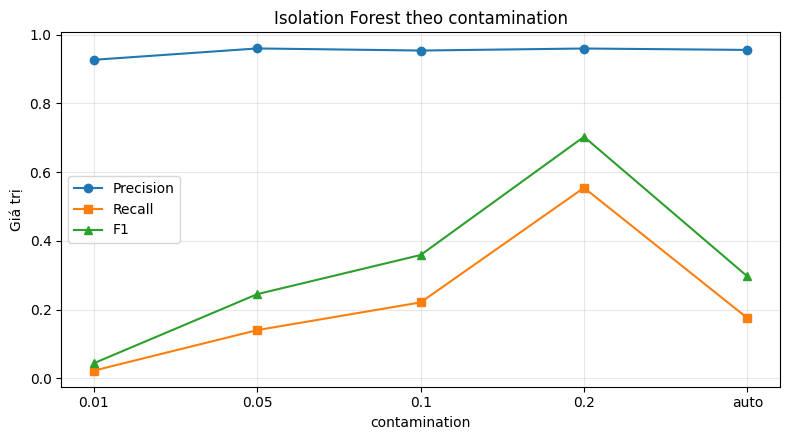

In [5]:
# Isolation Forest dựa trên một nhận xét đơn giản: mẫu bất thường thì DỄ BỊ
# CÔ LẬP. Thuật toán dựng nhiều cây bằng cách lặp lại việc chọn ngẫu nhiên
# một đặc trưng và một điểm cắt ngẫu nhiên. Mẫu nằm ở vùng thưa sẽ bị tách ra
# chỉ sau vài lần cắt, còn mẫu nằm giữa vùng dày đặc cần rất nhiều lần cắt.
# Độ sâu trung bình để cô lập một mẫu, lấy qua tất cả các cây, chính là thước
# đo mức bất thường — không cần biết mẫu nào là tấn công.
#
# contamination là tỷ lệ mẫu mà ta GIẢ ĐỊNH là bất thường; sklearn dùng nó để
# đặt ngưỡng cho hàm predict(). Lưu ý: nó KHÔNG ảnh hưởng tới điểm bất thường,
# chỉ ảnh hưởng tới chỗ cắt ngưỡng — nên AUC không đổi theo contamination.
rows = []
for c in CONTAM_GRID + ["auto"]:
    m = IsolationForest(n_estimators=N_TREES, contamination=c,
                        random_state=SEED, n_jobs=-1).fit(Z_fit)
    yp = (m.predict(Z_te) == -1).astype(int)
    rows.append(evaluate(y_te, yp, anomaly_score(m, Z_te), str(c)))

iso_df = pd.DataFrame(rows).set_index("model").round(4)
iso_df.index.name = "contamination"
print(iso_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])
print(f"\nAUC gần như không đổi qua các giá trị contamination "
      f"(khoảng {iso_df['auc'].mean():.4f}) — đúng như dự đoán.")
print(CONTAM_COMMENT)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
x = range(len(iso_df))
ax1.plot(x, iso_df["prec"], marker="o", label="Precision")
ax1.plot(x, iso_df["rec"], marker="s", label="Recall")
ax1.plot(x, iso_df["f1"], marker="^", label="F1")
ax1.set_xticks(list(x), [str(i) for i in iso_df.index])
ax1.set_xlabel("contamination")
ax1.set_ylabel("Giá trị")
ax1.set_title("Isolation Forest theo contamination")
ax1.legend()
ax1.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A3. Đặt Ngưỡng Từ Phân Phối Điểm Trên Tập Train

           prec     rec      f1  f1_macro     thr
phân vị                                          
90.0     0.9535  0.2211  0.3589    0.2936  0.4840
95.0     0.9596  0.1405  0.2451    0.2323  0.5308
97.5     0.9541  0.0713  0.1326    0.1715  0.5636
99.0     0.9266  0.0227  0.0443    0.1244  0.5927
99.5     0.9231  0.0093  0.0183    0.1110  0.6199

→ Phân vị cho F1 cao nhất: 90.0 (ngưỡng = 0.4840)

Nhận xét: Recall cực thấp ở mọi phân vị — chỉ 0,221 ngay cả ở phân vị 90.
Nghĩa là Isolation Forest bỏ sót gần 80% mã độc. Precision tuy cao (0,95)
nhưng với mức Recall đó thì mô hình gần như vô dụng.
Biểu đồ phân bố bên phải cho thấy nguyên nhân: điểm bất thường của mã độc
CHỒNG LẤN gần như hoàn toàn với file lành tính. Giải thích hợp lý: mã độc được
biên dịch bằng cùng những trình biên dịch, đóng gói bằng cùng những packer
thương mại như phần mềm hợp pháp — nên PE header của chúng trông "bình
thường". Chúng không phải ngoại lai về mặt thống kê.


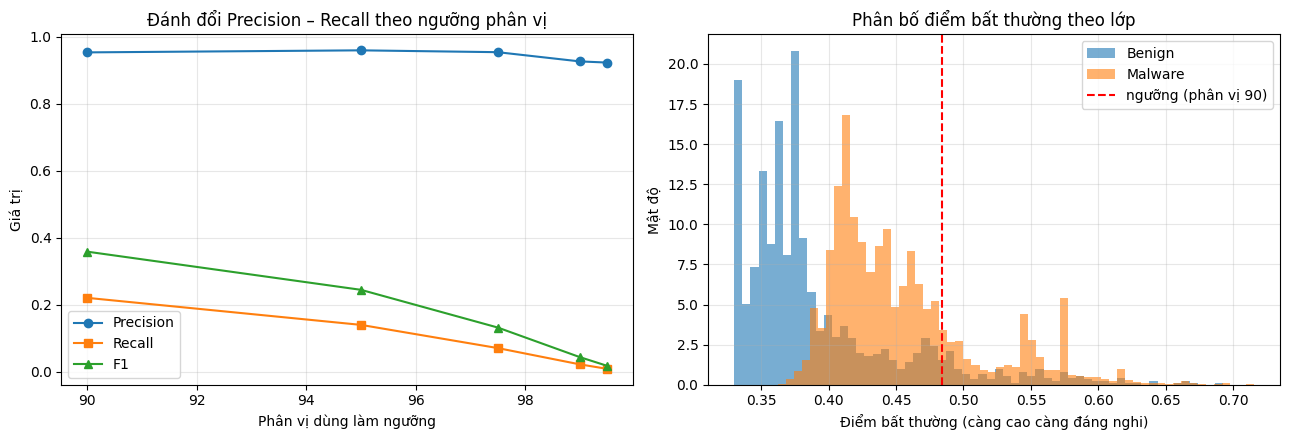

In [6]:
# Dùng contamination để đặt ngưỡng có một nhược điểm: ta phải ĐOÁN trước tỷ
# lệ tấn công trong dữ liệu sẽ gặp. Cách thực tế hơn: đặt ngưỡng từ chính
# phân phối điểm bất thường trên TẬP TRAIN (vốn chỉ gồm mẫu lành tính).
#
# Ví dụ lấy phân vị 95: ta chấp nhận cảnh báo giả khoảng 5% số mẫu lành tính.
# Cách này gắn trực tiếp với ràng buộc vận hành "mỗi ngày tôi chịu được bao
# nhiêu cảnh báo giả", thay vì với một giả định về tỷ lệ tấn công.
iso = IsolationForest(n_estimators=N_TREES, contamination="auto",
                      random_state=SEED, n_jobs=-1).fit(Z_fit)
s_fit = anomaly_score(iso, Z_fit)    # điểm trên tập train (chỉ lành tính)
s_te = anomaly_score(iso, Z_te)

rows = []
for p in PCTL_GRID:
    thr = np.percentile(s_fit, p)
    r = evaluate(y_te, (s_te >= thr).astype(int), s_te, p)
    r["thr"] = thr
    rows.append(r)

pct_df = pd.DataFrame(rows).set_index("model").round(4)
pct_df.index.name = "phân vị"
print(pct_df[["prec", "rec", "f1", "f1_macro", "thr"]])

PCTL_BEST = float(pct_df["f1"].idxmax())
THR_ISO = float(np.percentile(s_fit, PCTL_BEST))
print(f"\n→ Phân vị cho F1 cao nhất: {PCTL_BEST} (ngưỡng = {THR_ISO:.4f})")
print(PCTL_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(pct_df.index, pct_df["prec"], marker="o", label="Precision")
axes[0].plot(pct_df.index, pct_df["rec"], marker="s", label="Recall")
axes[0].plot(pct_df.index, pct_df["f1"], marker="^", label="F1")
axes[0].set_xlabel("Phân vị dùng làm ngưỡng")
axes[0].set_ylabel("Giá trị")
axes[0].set_title("Đánh đổi Precision – Recall theo ngưỡng phân vị")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].hist(s_te[y_te == 0], bins=60, alpha=.6, density=True,
             label=TARGET_NAMES[0])
axes[1].hist(s_te[y_te == 1], bins=60, alpha=.6, density=True,
             label=TARGET_NAMES[1])
axes[1].axvline(THR_ISO, color="red", ls="--",
                label=f"ngưỡng (phân vị {PCTL_BEST:g})")
axes[1].set_xlabel("Điểm bất thường (càng cao càng đáng nghi)")
axes[1].set_ylabel("Mật độ")
axes[1].set_title("Phân bố điểm bất thường theo lớp")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A4. One-Class SVM – Tham Số nu Và gamma

Dò 12 cấu hình trên 3,476 mẫu mất 14.3 giây

  nu gamma   prec    rec     f1    auc
0.20   0.1 0.9686 0.8654 0.9141 0.8790
0.10   0.1 0.9783 0.7400 0.8426 0.8582
0.01   0.1 0.9798 0.7282 0.8355 0.8471
0.05   0.1 0.9795 0.7277 0.8350 0.8472
0.20 scale 0.9652 0.6863 0.8022 0.8018

→ Cấu hình tốt nhất: nu=0.2, gamma=0.1 (F1 = 0.9141)

Nhận xét: One-Class SVM với nu=0,2 và gamma=0,1 đạt F1 0,9141 — cao hơn hẳn
Isolation Forest. Đáng chú ý là gamma=0,1 thắng ở mọi giá trị nu, tức biên bao
cần khá cục bộ. Nhưng hãy giữ sự thận trọng: phần A6 sẽ cho thấy con số 0,91
này vẫn chưa vượt được mốc so sánh tầm thường.


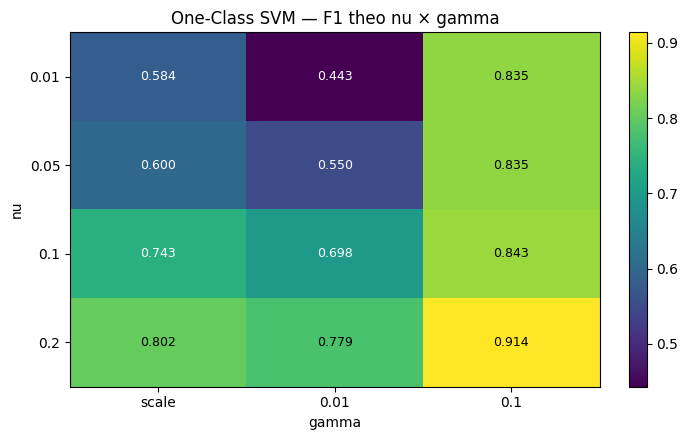

In [7]:
# One-Class SVM học một BIÊN BAO quanh vùng dữ liệu bình thường trong không
# gian kernel. Mẫu nằm ngoài biên bị coi là bất thường.
#
# nu là tham số then chốt, mang hai nghĩa cùng lúc: chặn trên tỷ lệ mẫu train
# bị coi là ngoại lai, và chặn dưới tỷ lệ mẫu train trở thành support vector.
# nu nhỏ → biên bao chặt quanh dữ liệu, ít báo động nhưng dễ bỏ sót;
# nu lớn → biên lỏng hơn, nhiều báo động hơn.
#
# Vì One-Class SVM đắt theo bình phương số mẫu, ta huấn luyện trên tập con
# Z_sub (xem phần cấu hình).
rows = []
t0 = time.perf_counter()
for nu in NU_GRID:
    for g in OCSVM_GAMMA:
        m = OneClassSVM(kernel="rbf", nu=nu, gamma=g).fit(Z_sub)
        yp = (m.predict(Z_te) == -1).astype(int)
        r = evaluate(y_te, yp, anomaly_score(m, Z_te), f"{nu}|{g}")
        r["nu"], r["gamma"] = nu, str(g)
        rows.append(r)
oc_time = time.perf_counter() - t0

oc_df = pd.DataFrame(rows)
print(f"Dò {len(rows)} cấu hình trên {Z_sub.shape[0]:,} mẫu "
      f"mất {oc_time:.1f} giây")
print()
print(oc_df.sort_values("f1", ascending=False)
      .head(5)[["nu", "gamma", "prec", "rec", "f1", "auc"]].round(4)
      .to_string(index=False))

bo = oc_df.loc[oc_df["f1"].idxmax()]
NU_BEST = float(bo["nu"])
G_BEST = bo["gamma"] if bo["gamma"] == "scale" else float(bo["gamma"])
print(f"\n→ Cấu hình tốt nhất: nu={NU_BEST:g}, gamma={bo['gamma']} "
      f"(F1 = {bo['f1']:.4f})")
print(OCSVM_COMMENT)

piv = oc_df.pivot(index="nu", columns="gamma", values="f1")
piv = piv[[str(g) for g in OCSVM_GAMMA]]
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(piv.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(piv.columns)), piv.columns)
ax.set_yticks(range(len(piv.index)), [f"{v:g}" for v in piv.index])
ax.set_xlabel("gamma")
ax.set_ylabel("nu")
ax.set_title("One-Class SVM — F1 theo nu × gamma")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                color="white" if v < piv.values.max() * .85 else "black",
                fontsize=9)
plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()
plt.show()


### A5. Local Outlier Factor – Mật Độ Cục Bộ

Dò 5 giá trị n_neighbors mất 1.5 giây

               prec     rec      f1  f1_macro     auc
n_neighbors                                          
5            0.9670  0.6819  0.7998    0.5896  0.7897
10           0.9639  0.6202  0.7548    0.5480  0.7485
20           0.9558  0.5242  0.6771    0.4848  0.7184
35           0.9429  0.4256  0.5864    0.4199  0.6499
50           0.9450  0.5105  0.6628    0.4683  0.7615

→ n_neighbors tốt nhất: 5 (F1 = 0.7998)

Nhận xét: LOF tốt nhất ở k=5 (0,7998) và GIẢM đơn điệu khi k tăng — ngược
hẳn với bộ dữ liệu của CV4.1 (nơi k lớn thắng). Điều này nói rằng mã độc PE
tạo thành rất nhiều cụm NHỎ: xét mật độ trong phạm vi 5 láng giềng thì thấy
khác biệt, mở rộng ra 50 láng giềng thì khác biệt bị hòa tan.
Phù hợp với hiểu biết miền: mỗi họ mã độc hoặc mỗi packer tạo một cụm riêng.


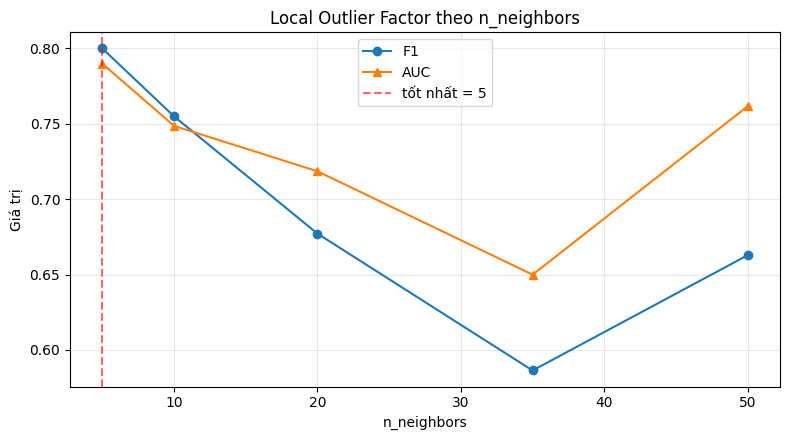

In [8]:
# Local Outlier Factor so sánh MẬT ĐỘ CỤC BỘ quanh một mẫu với mật độ quanh
# các láng giềng của nó. Nếu mẫu nằm ở vùng thưa hơn hẳn so với láng giềng
# thì nó bất thường. Khác với Isolation Forest (nhìn toàn cục), LOF bắt được
# bất thường cục bộ — mẫu nằm ở rìa một cụm dày.
#
# Tham số n_neighbors quyết định "cục bộ" rộng bao nhiêu. Phải đặt
# novelty=True mới dùng được để dự đoán trên dữ liệu mới.
rows = []
t0 = time.perf_counter()
for k in K_GRID:
    m = LocalOutlierFactor(n_neighbors=k, novelty=True).fit(Z_sub)
    yp = (m.predict(Z_te) == -1).astype(int)
    rows.append(evaluate(y_te, yp, anomaly_score(m, Z_te), k))
lof_time = time.perf_counter() - t0

lof_df = pd.DataFrame(rows).set_index("model").round(4)
lof_df.index.name = "n_neighbors"
print(f"Dò {len(K_GRID)} giá trị n_neighbors mất {lof_time:.1f} giây")
print()
print(lof_df[["prec", "rec", "f1", "f1_macro", "auc"]])

K_BEST = int(lof_df["f1"].idxmax())
print(f"\n→ n_neighbors tốt nhất: {K_BEST} (F1 = {lof_df.loc[K_BEST, 'f1']:.4f})")
print(LOF_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(lof_df.index, lof_df["f1"], marker="o", label="F1")
ax.plot(lof_df.index, lof_df["auc"], marker="^", label="AUC")
ax.axvline(K_BEST, color="red", ls="--", alpha=.6, label=f"tốt nhất = {K_BEST}")
ax.set_xlabel("n_neighbors")
ax.set_ylabel("Giá trị")
ax.set_title("Local Outlier Factor theo n_neighbors")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A6. So Sánh Ba Phương Pháp (Kèm Mốc So Sánh Tầm Thường)

Tỷ lệ lớp dương trong tập test: 88.7%
MỐC TẦM THƯỜNG — gắn cờ mọi mẫu là malware: F1 = 0.9400 | F1-macro = 0.4700

                                 prec     rec      f1  f1_macro     auc
model                                                                  
Isolation Forest (phân vị 90)  0.9535  0.2211  0.3589    0.2936  0.8339
One-Class SVM (nu=0.2)         0.9686  0.8654  0.9141    0.7324  0.8790
Local Outlier Factor (k=5)     0.9670  0.6819  0.7998    0.5896  0.7897

   Isolation Forest (phân vị 90)      KHÔNG VƯỢT mốc tầm thường về F1
   One-Class SVM (nu=0.2)             KHÔNG VƯỢT mốc tầm thường về F1
   Local Outlier Factor (k=5)         KHÔNG VƯỢT mốc tầm thường về F1

── Trên tập test CÂN BẰNG (1,490 lành tính / 1,490 tấn công), mốc tầm thường F1 = 0.6667 ──
                        prec     rec      f1  f1_macro     auc
model                                                         
Isolation Forest      0.7169  0.2141  0.3297    0.5037  0.8322
One-Class SVM         0.7961  0.

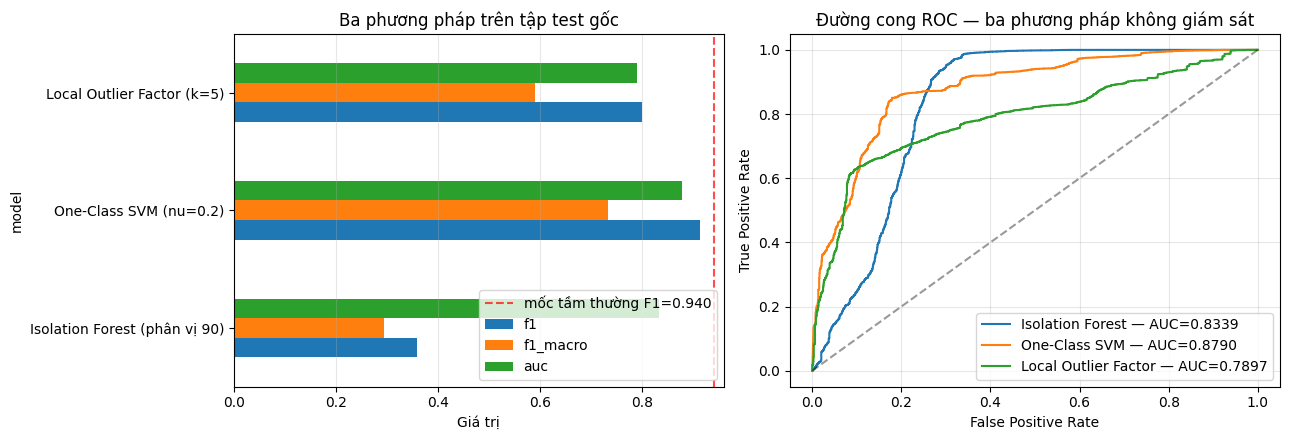

In [9]:
# So sánh ba phương pháp tại cấu hình tốt nhất của mỗi phương pháp.
#
# ⚠ TRƯỚC KHI ĐỌC CÁC CON SỐ: tập test của bài này gồm toàn bộ mẫu lành tính
# còn lại cộng với toàn bộ mẫu tấn công, nên tỷ lệ lớp dương có thể rất cao.
# Khi đó F1 bị thổi phồng: chỉ cần GẮN CỜ MỌI MẪU là tấn công đã đạt F1 rất
# cao mà không học được gì. Vì vậy ta in kèm:
#   (1) mốc so sánh tầm thường "gắn cờ tất cả";
#   (2) F1-macro — trung bình F1 của cả hai lớp, không bị lớp đa số chi phối;
#   (3) AUC — không phụ thuộc tỷ lệ lớp;
#   (4) kết quả trên một tập test CÂN BẰNG lấy mẫu lại.
iso_best = IsolationForest(n_estimators=N_TREES, contamination="auto",
                           random_state=SEED, n_jobs=-1).fit(Z_fit)
s_iso = anomaly_score(iso_best, Z_te)
yp_iso = (s_iso >= THR_ISO).astype(int)

oc_best = OneClassSVM(kernel="rbf", nu=NU_BEST, gamma=G_BEST).fit(Z_sub)
s_oc = anomaly_score(oc_best, Z_te)
yp_oc = (oc_best.predict(Z_te) == -1).astype(int)

lof_best = LocalOutlierFactor(n_neighbors=K_BEST, novelty=True).fit(Z_sub)
s_lof = anomaly_score(lof_best, Z_te)
yp_lof = (lof_best.predict(Z_te) == -1).astype(int)

rows = [
    evaluate(y_te, yp_iso, s_iso, f"Isolation Forest (phân vị {PCTL_BEST:g})"),
    evaluate(y_te, yp_oc, s_oc, f"One-Class SVM (nu={NU_BEST:g})"),
    evaluate(y_te, yp_lof, s_lof, f"Local Outlier Factor (k={K_BEST})"),
]
cmp_df = pd.DataFrame(rows).set_index("model").round(4)

ones = np.ones_like(y_te)
triv_f1 = f1_score(y_te, ones, zero_division=0)
triv_f1m = f1_score(y_te, ones, average="macro", zero_division=0)

print(f"Tỷ lệ lớp dương trong tập test: {y_te.mean()*100:.1f}%")
print(f"MỐC TẦM THƯỜNG — gắn cờ mọi mẫu là {TARGET_NAMES[1].lower()}: "
      f"F1 = {triv_f1:.4f} | F1-macro = {triv_f1m:.4f}")
print()
print(cmp_df[["prec", "rec", "f1", "f1_macro", "auc"]])
print()
for nm, v in cmp_df.iterrows():
    print(f"   {nm[:34]:34s} {'VƯỢT' if v['f1'] > triv_f1 else 'KHÔNG VƯỢT'} "
          f"mốc tầm thường về F1")

# ── Tập test cân bằng ──────────────────────────────────────────────────────
pos, neg = np.where(y_te == 1)[0], np.where(y_te == 0)[0]
if len(pos) > len(neg):
    pos = np.random.RandomState(SEED).choice(pos, size=len(neg), replace=False)
bal = np.sort(np.concatenate([pos, neg]))
y_b = y_te[bal]
rows_b = [
    evaluate(y_b, yp_iso[bal], s_iso[bal], "Isolation Forest"),
    evaluate(y_b, yp_oc[bal], s_oc[bal], "One-Class SVM"),
    evaluate(y_b, yp_lof[bal], s_lof[bal], "Local Outlier Factor"),
]
bal_df = pd.DataFrame(rows_b).set_index("model").round(4)
print(f"\n── Trên tập test CÂN BẰNG ({int((y_b==0).sum()):,} lành tính / "
      f"{int((y_b==1).sum()):,} tấn công), mốc tầm thường F1 = "
      f"{f1_score(y_b, np.ones_like(y_b), zero_division=0):.4f} ──")
print(bal_df[["prec", "rec", "f1", "f1_macro", "auc"]])
print(COMPARE_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cmp_df[["f1", "f1_macro", "auc"]].plot.barh(ax=axes[0])
axes[0].axvline(triv_f1, color="red", ls="--", alpha=.7,
                label=f"mốc tầm thường F1={triv_f1:.3f}")
axes[0].set_xlabel("Giá trị")
axes[0].set_title("Ba phương pháp trên tập test gốc")
axes[0].legend()
axes[0].grid(axis="x", alpha=.3)

for nm, sc in [("Isolation Forest", s_iso), ("One-Class SVM", s_oc),
               ("Local Outlier Factor", s_lof)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[1].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Đường cong ROC — ba phương pháp không giám sát")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A7. Cái Giá Của Việc Không Dùng Nhãn Tấn Công

Random Forest được huấn luyện trên 11,648 mẫu CÓ NHÃN (trong đó 8,172 mẫu tấn công)
Phương pháp không giám sát chỉ dùng 3,476 mẫu lành tính, KHÔNG dùng một nhãn tấn công nào

                                                   prec     rec      f1  \
model                                                                     
Tốt nhất không giám sát: One-Class SVM (nu=0.2)  0.9686  0.8654  0.9141   
Random Forest CÓ giám sát                        0.9895  0.9980  0.9937   

                                                 f1_macro     auc  
model                                                              
Tốt nhất không giám sát: One-Class SVM (nu=0.2)    0.7324  0.8790  
Random Forest CÓ giám sát                          0.9894  0.9983  

Khoảng cách F1: +0.0796 | khoảng cách AUC: +0.1193

Nhận xét: khoảng cách ở đây RẤT LỚN. Random Forest có giám sát đạt F1 0,9937
và AUC 0,9983, trong khi phương pháp không giám sát tốt nhất chỉ 0,9141 và
0,8790 — chênh khoảng 0,12 AUC.
So sánh với bộ 

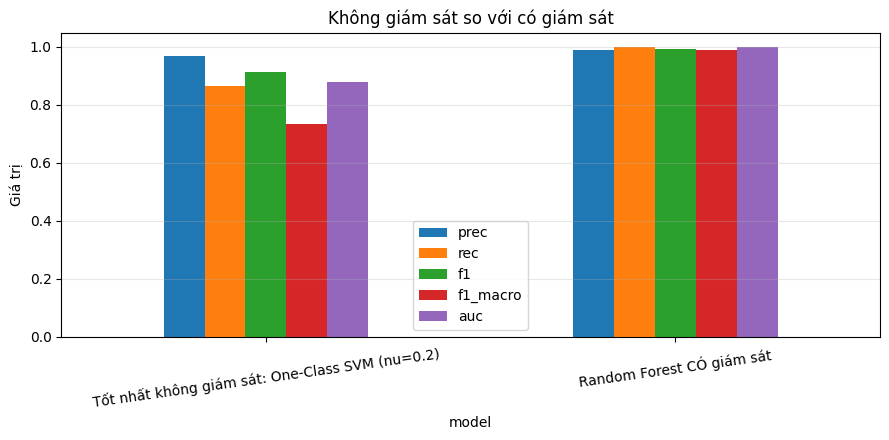

In [10]:
# Câu hỏi quan trọng: nếu ta CÓ nhãn tấn công thì mô hình tốt hơn bao nhiêu?
# Phần này huấn luyện một Random Forest có giám sát trên cùng dữ liệu nhưng
# được dùng cả nhãn tấn công, rồi so với phương pháp không giám sát tốt nhất.
#
# Đây là cách định lượng CÁI GIÁ của việc không có nhãn — con số này quyết
# định việc có nên đầu tư vào việc gán nhãn dữ liệu hay không.
X_a, X_b, y_a, y_b2 = train_test_split(X_sup, y_sup, test_size=TEST_SIZE,
                                       random_state=SEED, stratify=y_sup)
sc_sup = StandardScaler().fit(X_a)
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(sc_sup.transform(X_a), y_a)
Zb = sc_sup.transform(X_b)
rf_res = evaluate(y_b2, rf.predict(Zb), rf.predict_proba(Zb)[:, 1],
                  "Random Forest CÓ giám sát")

best_unsup = cmp_df["f1"].idxmax()
print(f"Random Forest được huấn luyện trên {len(y_a):,} mẫu CÓ NHÃN "
      f"(trong đó {int(y_a.sum()):,} mẫu tấn công)")
print(f"Phương pháp không giám sát chỉ dùng {Z_fit.shape[0]:,} mẫu lành tính, "
      f"KHÔNG dùng một nhãn tấn công nào")
print()
gap = pd.DataFrame([
    dict(cmp_df.loc[best_unsup], model=f"Tốt nhất không giám sát: {best_unsup[:30]}"),
    rf_res,
]).set_index("model").round(4)
print(gap[["prec", "rec", "f1", "f1_macro", "auc"]])
print(f"\nKhoảng cách F1: {rf_res['f1'] - cmp_df.loc[best_unsup, 'f1']:+.4f} | "
      f"khoảng cách AUC: {rf_res['auc'] - cmp_df.loc[best_unsup, 'auc']:+.4f}")
print(SUPERVISED_COMMENT)

ax = gap[["prec", "rec", "f1", "f1_macro", "auc"]].plot.bar(figsize=(9, 4.5), rot=8)
ax.set_ylabel("Giá trị")
ax.set_title("Không giám sát so với có giám sát")
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A8. Cần Bao Nhiêu Dữ Liệu Lành Tính Là Đủ?

                                       prec     rec      f1  f1_macro     auc
số mẫu lành tính dùng để huấn luyện                                          
250                                  0.9375  0.1889  0.3144    0.2664  0.8262
500                                  0.9455  0.2035  0.3350    0.2789  0.8354
1000                                 0.9511  0.1833  0.3074    0.2649  0.8452
2000                                 0.9458  0.1885  0.3143    0.2678  0.8336
3476                                 0.9535  0.2211  0.3589    0.2936  0.8339

Nhận xét: hiệu năng gần như KHÔNG đổi khi tăng số mẫu lành tính từ 250 lên
3.476 — F1 dao động quanh 0,31–0,36 và AUC quanh 0,83–0,85. Nghĩa là thêm dữ
liệu lành tính không giúp gì.
Đây là kết luận có giá trị thực tế: hạn chế của phương pháp không nằm ở lượng
dữ liệu mà ở BẢN CHẤT bài toán — mã độc PE không phải ngoại lai thống kê. Muốn
cải thiện thì phải đổi đặc trưng (ví dụ thêm phân tích động, chuỗi API call như
Bài 4) hoặc chuyển sang mô hình có

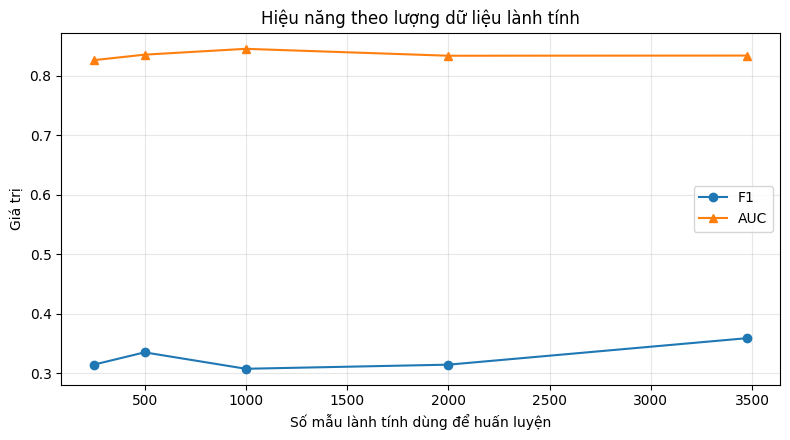

In [11]:
# Với phương pháp không giám sát, câu hỏi thực tế là: cần bao nhiêu dữ liệu
# LÀNH TÍNH để mô hình ổn định? Nếu chỉ cần vài trăm mẫu thì việc triển khai
# ở một hệ thống mới trở nên rất rẻ.
rows = []
for n in CURVE_GRID + [Z_fit.shape[0]]:
    if n > Z_fit.shape[0]:
        continue
    m = IsolationForest(n_estimators=N_TREES, contamination="auto",
                        random_state=SEED, n_jobs=-1).fit(Z_fit[:n])
    sf = anomaly_score(m, Z_fit[:n])
    st = anomaly_score(m, Z_te)
    thr = np.percentile(sf, PCTL_BEST)
    rows.append(evaluate(y_te, (st >= thr).astype(int), st, n))

cur_df = pd.DataFrame(rows).set_index("model").round(4)
cur_df.index.name = "số mẫu lành tính dùng để huấn luyện"
print(cur_df[["prec", "rec", "f1", "f1_macro", "auc"]])
print(CURVE_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cur_df.index, cur_df["f1"], marker="o", label="F1")
ax.plot(cur_df.index, cur_df["auc"], marker="^", label="AUC")
ax.set_xlabel("Số mẫu lành tính dùng để huấn luyện")
ax.set_ylabel("Giá trị")
ax.set_title("Hiệu năng theo lượng dữ liệu lành tính")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. AUC của Isolation Forest chỉ 0,834 — thấp hơn hẳn 0,970 của bộ dữ liệu lưu lượng mạng ở bài tương ứng của CV4.1.
2. Recall của Isolation Forest cực thấp (0,221 ngay ở phân vị 90): nó bỏ sót gần 80% mã độc. Biểu đồ phân bố cho thấy điểm bất thường của hai lớp chồng lấn gần như hoàn toàn.
3. One-Class SVM tốt nhất (0,9141), LOF tốt nhất ở `k=5` và giảm đơn điệu khi `k` tăng — ngược với bộ dữ liệu của CV4.1.
4. **Không phương pháp nào vượt được mốc tầm thường về F1 (0,94).** Chỉ khi xem F1-macro và tập cân bằng mới thấy OC-SVM (0,826) và LOF (0,743) thực sự học được điều gì đó.
5. Khoảng cách với mô hình có giám sát rất lớn: 0,879 so với 0,998 về AUC.
6. Tăng số mẫu lành tính từ 250 lên 3.476 gần như không cải thiện gì — hạn chế nằm ở bản chất bài toán, không ở lượng dữ liệu.

**Câu hỏi thảo luận**

1. Vì sao mã độc PE lại KHÔNG phải ngoại lai thống kê so với file lành tính? Hãy lập luận từ việc cả hai được biên dịch và đóng gói bằng cùng những công cụ.
2. Mốc tầm thường đạt F1 = 0,94 trong khi OC-SVM chỉ 0,9141. Nếu một báo cáo chỉ ghi "mô hình đạt F1 = 0,91" thì người đọc sẽ hiểu sai như thế nào? Hãy nêu nguyên tắc báo cáo kết quả mà bạn rút ra.
3. LOF ở đây tốt nhất với `k=5` còn ở bộ dữ liệu của CV4.1 tốt nhất với `k=50`. Hãy giải thích sự khác biệt dựa trên cấu trúc cụm của hai loại dữ liệu.
4. Learning curve ở phần A8 gần như nằm ngang. Hãy nêu hai hướng cải thiện KHÔNG phải là "thu thập thêm file sạch", và giải thích vì sao chúng hứa hẹn hơn.
5. So sánh khoảng cách không-giám-sát với có-giám-sát ở bài này (0,12 AUC) và ở bài tương ứng của CV4.1 (0,04 AUC). Kết luận gì về giá trị của việc gán nhãn trên từng loại dữ liệu?
6. Nếu được yêu cầu triển khai phát hiện bất thường cho một sản phẩm antivirus dựa trên kết quả bài này, bạn sẽ đặt nó ở vị trí nào trong hệ thống và vì sao không dùng làm cơ chế chặn chính?
7. Bài 4 của công việc 4.2 dùng chuỗi API call (đặc trưng động) thay vì PE header (đặc trưng tĩnh). Hãy dự đoán phát hiện bất thường sẽ hoạt động tốt hơn hay kém hơn trên dữ liệu đó, và giải thích.
